# GM_F123 barnyard — human vs mouse read counts per cell

Species-mixing (GM12878 human + F123 mouse) scNOMe-HiC, aligned to the combined
**hg38_mm10** reference. Species is assigned by contig name: mouse = `mm10_chr*`,
human = everything else (`chr*`).

**x = reads mapped to human, y = reads mapped to mouse** (one point per cell).

Counts come from `species_read_counts.tsv` (built by
`code/extract_species_counts.sh`):
- `*_hq_reads` — proper-pair, MapQ≥30, deduplicated primary reads (used here).
- `*_all_reads` — every mapped record per contig (idxstats; incl. dups/low-MapQ).

Classification (Human / Mouse / Mixed) is left as a **discussion** — the
provisional thresholds below are a starting point, tweak `F_HUMAN`, `F_MOUSE`,
`MIN_READS` and re-run to explore.

In [1]:
# --- environment ---------------------------------------------------------------
# This notebook was written against the `scnomehic` conda environment.
#     conda env create -f env/scnomehic.yml && conda activate scnomehic
# See env/README.md for which notebook uses which environment.
_ENV_EXPECTED = "scnomehic"
import os as _os, sys as _sys
if _os.path.basename(_sys.prefix) != _ENV_EXPECTED:
    print(f"[env] expected the '{_ENV_EXPECTED}' environment, running in "
          f"'{_os.path.basename(_sys.prefix)}' ({_sys.prefix}). See env/README.md.",
          file=_sys.stderr)

# --- repo paths: edit paths.yaml at the repository root, not this notebook ---
# Cached so that re-running this cell still works after it has chdir'd away.
import os as _os, sys as _sys
if "REPO_ROOT" not in globals():
    _r = _os.getcwd()
    while _r != "/" and not _os.path.exists(_os.path.join(_r, "paths.py")):
        _r = _os.path.dirname(_r)
    assert _os.path.exists(_os.path.join(_r, "paths.py")), \
        "paths.py not found above the working directory -- start Jupyter inside the repository"
    REPO_ROOT = _r
_sys.path.insert(0, REPO_ROOT)
from paths import DATA, REFERENCE, SOFTWARE, WORK, TMP, CONDA_SH, CONDA_ENVS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(WORK + "/barnyard_mixing/species_read_counts.tsv", sep="\t")
# Use high-quality (dedup, MapQ30, proper-pair) reads for the barnyard.
df["human"] = df["human_hq_reads"]
df["mouse"] = df["mouse_hq_reads"]
df["total"] = df["human"] + df["mouse"]
df["human_frac"] = df["human"] / df["total"].where(df["total"] > 0)
print(f"{len(df)} cells")
print(df[["cell", "human", "mouse", "total", "human_frac"]]
      .sort_values("human_frac").to_string(index=False))

96 cells
             cell   human   mouse   total  human_frac
demul_sc53.TGACCA   11087  261269  272356    0.040708
demul_sc64.GCCAAT   41661  907601  949262    0.043888
demul_sc66.CGATGT   40123  831201  871324    0.046048
demul_sc67.CGATGT   15296  314302  329598    0.046408
demul_sc50.TGACCA   21177  414894  436071    0.048563
demul_sc66.TGACCA   25816  492813  518629    0.049777
demul_sc63.CGATGT   19579  370517  390096    0.050190
demul_sc65.GCCAAT   24181  445362  469543    0.051499
demul_sc59.TGACCA   41186  752893  794079    0.051866
demul_sc72.CGATGT   22731  410788  433519    0.052434
demul_sc52.CGATGT   55504  973746 1029250    0.053927
demul_sc54.TGACCA   69113 1203034 1272147    0.054328
demul_sc58.GCCAAT   21541  373486  395027    0.054530
demul_sc49.CGATGT   16143  278481  294624    0.054792
demul_sc57.TGACCA   67605 1158672 1226277    0.055130
demul_sc68.ATCACG   40118  657709  697827    0.057490
demul_sc63.ATCACG   28657  463571  492228    0.058219
demul_sc54.CGATGT  

## Main plot — human vs mouse reads (log–log)

Log axes because per-cell depth spans ~3 orders of magnitude. The dashed line is
y = x (equal human/mouse). Barnyard experiments produce an **L-shape**: cells
hug the x-axis (human) or y-axis (mouse); points pulled toward the diagonal are
candidate **doublets / collisions**.

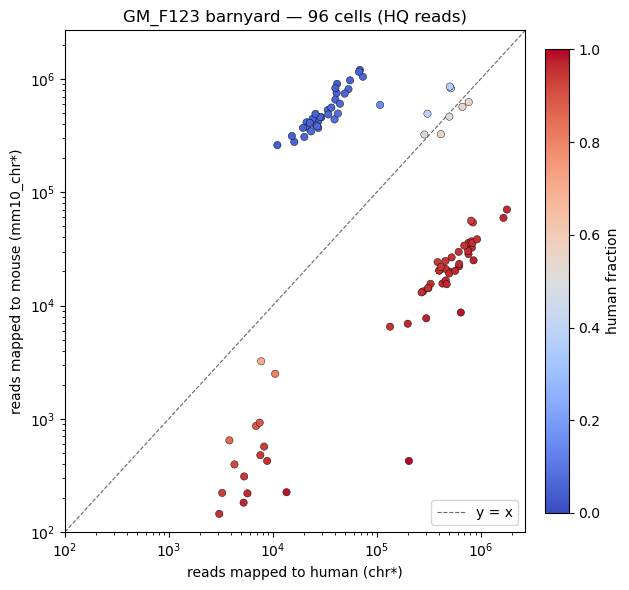

In [2]:
fig, ax = plt.subplots(figsize=(6.4, 6))
sc = ax.scatter(df["human"], df["mouse"], c=df["human_frac"], cmap="coolwarm",
                s=28, edgecolor="k", linewidth=0.3, vmin=0, vmax=1, zorder=3)
lo, hi = 1e2, max(df[["human", "mouse"]].max()) * 1.5
ax.plot([lo, hi], [lo, hi], "k--", lw=0.8, alpha=0.6, zorder=1, label="y = x")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel("reads mapped to human (chr*)")
ax.set_ylabel("reads mapped to mouse (mm10_chr*)")
ax.set_title("GM_F123 barnyard — 96 cells (HQ reads)")
cb = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04); cb.set_label("human fraction")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("barnyard_scatter_loglog.pdf")
plt.show()

## Linear view (reads in thousands)

The classic barnyard L. Same data, linear axes — makes the high-depth doublets
along the diagonal obvious.

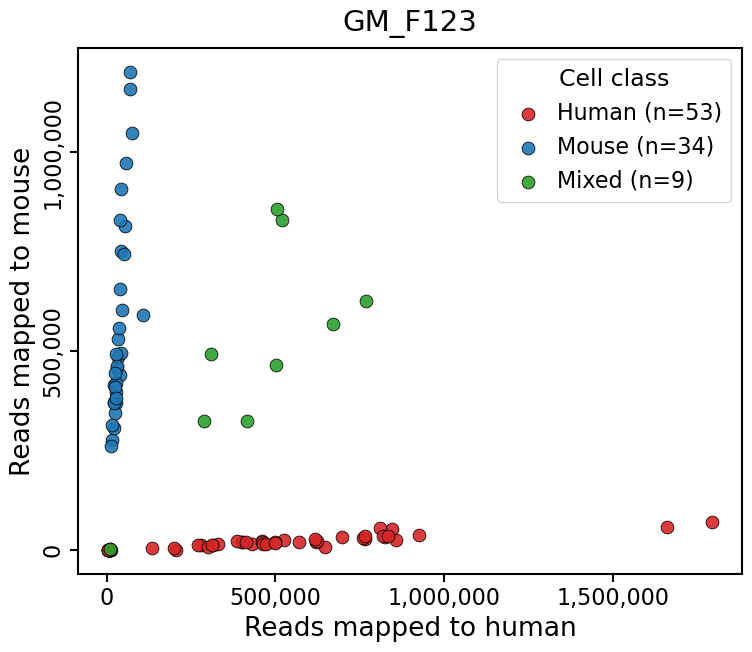

In [16]:
# Publication-style linear barnyard, coloured by a 3-way class (Human / Mouse /
# Mixed) from the human fraction. Thresholds match the classification below;
# adjust F_HUMAN / F_MOUSE to taste.
import matplotlib as mpl
from matplotlib.ticker import FuncFormatter

F_HUMAN, F_MOUSE = 0.80, 0.20

def species3(f):
    if f >= F_HUMAN:
        return "Human"
    if f <= F_MOUSE:
        return "Mouse"
    return "Mixed"

df["species3"] = df["human_frac"].apply(species3)
palette = {"Human": "#d62728", "Mouse": "#1f77b4", "Mixed": "#2ca02c"}

pub_style = {
    "font.size": 16,
    "axes.linewidth": 1.5,
    "pdf.fonttype": 42,   # keep text editable in Illustrator
    "ps.fonttype": 42,
    "savefig.bbox": "tight",
}
with mpl.rc_context(pub_style):
    fig, ax = plt.subplots(figsize=(7.8, 6.8))
    for cls in ["Human", "Mouse", "Mixed"]:
        sub = df[df["species3"] == cls]
        ax.scatter(sub["human"], sub["mouse"], s=85, alpha=0.9,
                   edgecolor="black", linewidth=0.6, c=palette[cls],
                   label=f"{cls} (n={len(sub)})")
    ax.set_xlabel(r"Reads mapped to human", fontsize=19)
    ax.set_ylabel(r"Reads mapped to mouse", fontsize=19)
    ax.set_title("GM_F123", fontsize=21, pad=12)
    ax.tick_params(axis="both", which="major", labelsize=16, length=6, width=1.5)
    # Fewer tick labels, and show the whole raw count with thousands separators
    # (no 1e6-style scientific offset).
    ax.locator_params(axis="x", nbins=4)
    ax.locator_params(axis="y", nbins=4)
    thousands = FuncFormatter(lambda v, pos: f"{int(v):,}")
    ax.xaxis.set_major_formatter(thousands)
    ax.yaxis.set_major_formatter(thousands)
    ax.tick_params(axis="y", labelrotation=90)  # vertical y tick numbers
    plt.setp(ax.get_yticklabels(), va="center")  # center each number on its tick mark
    ax.legend(title="Cell class", loc="upper right", fontsize=16,
              title_fontsize=17, handletextpad=0.3, borderpad=0.4)
    fig.tight_layout()
    fig.savefig("barnyard_scatter_linear.pdf")
    fig.savefig("barnyard_scatter_linear.png", dpi=300)
    plt.show()

## Human-fraction histogram — separation aid

If the sample is mostly singlets, `human_frac` is **bimodal** (piled near 0 =
mouse, near 1 = human); the trough between the modes is where a Human/Mouse cut
sits, and cells in the middle are the Mixed/doublet candidates.

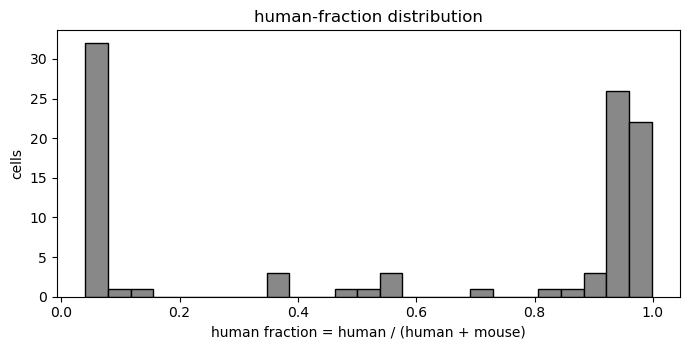

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(df["human_frac"].dropna(), bins=25, color="#888", edgecolor="k")
ax.set_xlabel("human fraction = human / (human + mouse)")
ax.set_ylabel("cells"); ax.set_title("human-fraction distribution")
fig.tight_layout()
fig.savefig("human_fraction_hist.pdf")
plt.show()

## Provisional classification (starting point for discussion)

Two knobs: a **fraction** cut (how pure a cell must be to call one species) and a
**minimum-reads** cut (below which the fraction is too noisy to trust). Adjust
and re-run.

cell_class
Human       40
Mouse       33
LowDepth    12
Mixed       11


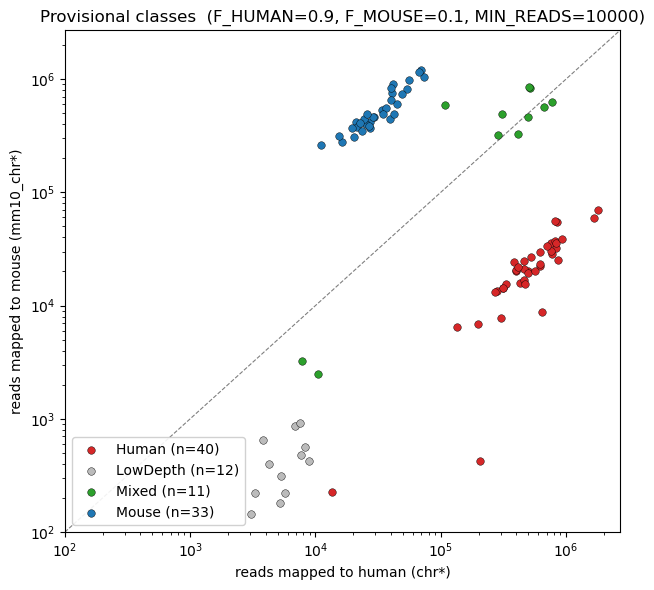


-- Mixed / LowDepth cells --
             cell  human  mouse   total  human_frac cell_class
demul_sc69.CGATGT 108054 591171  699225    0.154534      Mixed
demul_sc64.TGACCA 505968 857832 1363800    0.370999      Mixed
demul_sc70.GCCAAT 308538 494071  802609    0.384419      Mixed
demul_sc63.GCCAAT 518281 829192 1347473    0.384632      Mixed
demul_sc53.CGATGT 288237 323849  612086    0.470909      Mixed
demul_sc69.GCCAAT 500918 465665  966583    0.518236      Mixed
demul_sc69.ATCACG 669223 568509 1237732    0.540685      Mixed
demul_sc67.ATCACG 768975 626326 1395301    0.551118      Mixed
demul_sc53.GCCAAT 415790 325928  741718    0.560577      Mixed
demul_sc71.ATCACG   7750   3224   10974    0.706215      Mixed
demul_sc56.GCCAAT  10564   2501   13065    0.808573      Mixed
demul_sc71.CGATGT   3831    646    4477    0.855707   LowDepth
demul_sc56.ATCACG   6919    865    7784    0.888875   LowDepth
demul_sc57.GCCAAT   7501    926    8427    0.890115   LowDepth
demul_sc69.TGACCA   4288 

In [5]:
F_HUMAN   = 0.90   # human_frac >= this -> Human
F_MOUSE   = 0.10   # human_frac <= this -> Mouse
MIN_READS = 10000  # cells below this total are "low-depth" (fraction unreliable)

def classify(r):
    if r["total"] < MIN_READS:
        return "LowDepth"
    if r["human_frac"] >= F_HUMAN:
        return "Human"
    if r["human_frac"] <= F_MOUSE:
        return "Mouse"
    return "Mixed"

df["cell_class"] = df.apply(classify, axis=1)
print(df["cell_class"].value_counts().to_string())

colors = {"Human": "#d62728", "Mouse": "#1f77b4", "Mixed": "#2ca02c", "LowDepth": "#bbbbbb"}
fig, ax = plt.subplots(figsize=(6.4, 6))
for cls, sub in df.groupby("cell_class"):
    ax.scatter(sub["human"], sub["mouse"], s=30, edgecolor="k", linewidth=0.3,
               c=colors[cls], label=f"{cls} (n={len(sub)})", zorder=3)
lo, hi = 1e2, max(df[["human", "mouse"]].max()) * 1.5
ax.plot([lo, hi], [lo, hi], "k--", lw=0.8, alpha=0.5, zorder=1)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel("reads mapped to human (chr*)")
ax.set_ylabel("reads mapped to mouse (mm10_chr*)")
ax.set_title(f"Provisional classes  (F_HUMAN={F_HUMAN}, F_MOUSE={F_MOUSE}, MIN_READS={MIN_READS})")
ax.legend(loc="lower left", framealpha=0.9)
fig.tight_layout()
fig.savefig("barnyard_classified.pdf")
plt.show()

# List the Mixed + LowDepth cells for inspection.
print("\n-- Mixed / LowDepth cells --")
print(df[df["cell_class"].isin(["Mixed", "LowDepth"])]
      [["cell", "human", "mouse", "total", "human_frac", "cell_class"]]
      .sort_values("human_frac").to_string(index=False))

In [6]:
# Save the table with classes for downstream use.
df.to_csv("species_read_counts.classified.tsv", sep="\t", index=False)
print("wrote species_read_counts.classified.tsv")

wrote species_read_counts.classified.tsv
